# Results of the EE size dependence test
* Test run in notebook ""
* Include the minimum object area


In [3]:
import pandas as pd
import os
import ultraplot as uplt
import numpy as np

data = []
for file in os.listdir('../data/erosion_test'):
    case = file.split('.')[0]
    df = pd.read_csv('../data/erosion_test/' + file)
    df = df.astype(float)
    df['case_number'] = case.split('_')[0]
    df['satellite'] = case.split('_')[1]
    data.append(df)
df = df.reset_index(drop=True)

In [4]:
df = pd.concat(data)

In [5]:
df['length_scale'] = np.sqrt(df.area)
df['length_bin'] = np.digitize(df.length_scale, bins=np.arange(20, 200, 5))

In [6]:
df['bin_mean_length_scale'] = df[['length_scale', 'length_bin']].groupby('length_bin').transform('mean')
df['bin_mean_area'] = df[['area', 'length_bin']].groupby('length_bin').transform('mean')

In [9]:
columns = [c for c in df.columns if c not in ['case_number', 'satellite']]

In [22]:
lb_mean = df.loc[:, columns].groupby('length_bin').median()
lb_min = df.loc[:, columns].groupby('length_bin').quantile(0.25)
lb_max = df.loc[:, columns].groupby('length_bin').quantile(0.75)
plot_cols = ["ee_n{i}_area_err".format(i=i) for i in range(1, 11)]


Error definition: ee_nX_area_err = percent difference in area after erosion-expansion X times.

Finding: Objects with initial size 

/opt/miniconda3/envs/invclim/lib/python3.14/site-packages/ultraplot/axes/cartesian.py:1081: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  getattr(self, f"set_{s}lim")(lim)


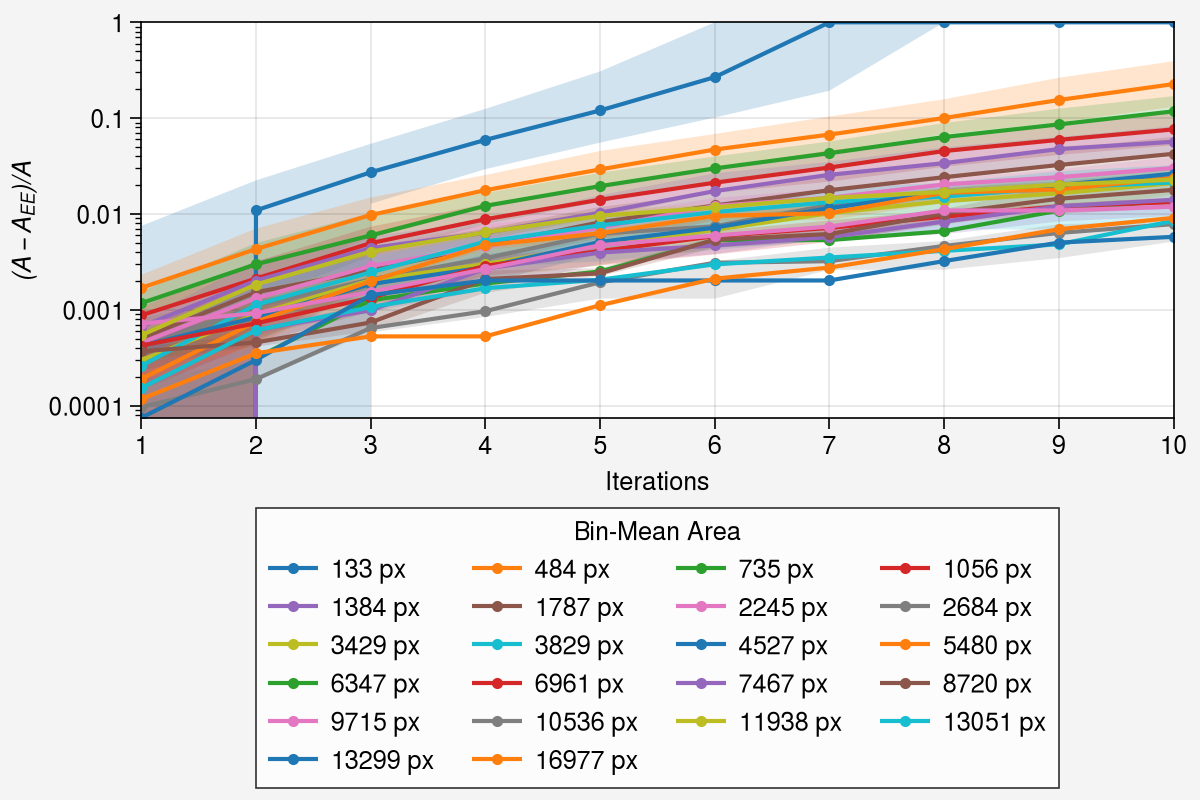

In [24]:

fig, ax = uplt.subplots(width=6, height=4)
for L in lb_mean.index:
    ax.plot(lb_mean.loc[L, plot_cols],
            fadedata=[
                lb_min.loc[L, plot_cols],
                lb_max.loc[L, plot_cols]
            ],
            marker='.', label='{a} px'.format(a = int(lb_mean.loc[L, 'area'].round(0))))

    ax.format(ylim=(0, 1), xformatter=[str(i) for i in range(1, 11)])
ax.legend(ncols=4, title='Bin-Mean Area', loc='b')
ax.format(ylim=(0, 1), ylabel="$(A - A_{EE}) / A$", xlabel='Iterations', yscale='log')

(array([6.000e+02, 1.053e+03, 6.630e+02, 4.930e+02, 3.330e+02, 2.180e+02,
        1.780e+02, 1.050e+02, 1.020e+02, 8.700e+01, 5.200e+01, 5.600e+01,
        3.200e+01, 1.600e+01, 2.500e+01, 2.400e+01, 1.100e+01, 8.000e+00,
        9.000e+00, 5.000e+00, 2.000e+00, 3.000e+00, 5.000e+00, 1.000e+00,
        1.000e+00, 2.000e+00, 3.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        2.000e+00, 3.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 0.000e+00,
        1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([  43. ,   79.2,  115.4,  151.6,  187.8,  224. ,  260.2,  296.4,
         332.6,  368.8,  405. ,  441.2,  477.4,  513.6,  549.8,  586. ,
         622.2,  658.4,  694.6,  730.8,  767. ,  803.2,  839.4,  875.6,
         911.8,  948. ,  984.2, 1020.4, 1056.6, 1092.8, 1129. , 1165.2,
        1201.4, 1237.6, 1273.8, 1310. , 1346.2, 1382.4, 1418.6, 1454.8,
        1491. , 

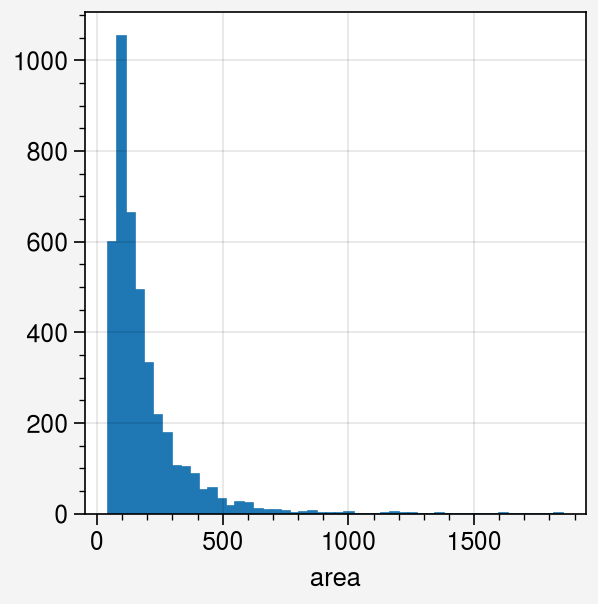

In [31]:
fig, ax = uplt.subplots()
ax.hist(df.loc[df.ee_n8_area_err > 0.1, 'area'], bins=50)